<a href="https://colab.research.google.com/github/U-mar-404/PE-LLM-Lab06_Revision_SimpleRNN/blob/main/Lab06_Revision_SimpleRNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Revision Lab: Text Classification with SimpleRNN (11 Steps)
**Prompt Engineering and LLM Applications | BSAI 7th Semester | Instructor: Iqra Riaz**

Revise the Lab 03 pipeline step by step. Next lab we replace `SimpleRNN` with **LSTM**, so understand *every* step here first.

```
Text → IDs → Padding → Embedding → SimpleRNN (h1…hT) → Dense + Sigmoid → Probability → Class
```
Run cells top to bottom. After each step, answer the **Check yourself** question before moving on.

## Setup

In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, Dense, Dropout
from sklearn.metrics import classification_report, confusion_matrix

np.random.seed(42); tf.random.set_seed(42)
VOCAB = 10000      # keep the 10,000 most frequent words
MAXLEN = 200       # every review becomes 200 tokens

## Step 1 — Text → Numbers
A network can only do maths on numbers, so each word becomes an **integer ID**. IMDB comes pre-encoded; IDs 0–3 are reserved (0 = padding, 1 = start, 2 = unknown), so real words are shifted by 3.

In [ ]:
(X_train_raw, y_train), (X_test_raw, y_test) = imdb.load_data(num_words=VOCAB)

print("Train reviews:", len(X_train_raw), "| Test reviews:", len(X_test_raw))
print("Labels: 0 = negative, 1 = positive | train balance:", np.bincount(y_train))
print("\nReview 0 as IDs:", X_train_raw[0][:15], "...")

word_index = imdb.get_word_index()
rev_index = {v: k for k, v in word_index.items()}
decode = lambda r: " ".join(rev_index.get(i - 3, "?") for i in r)
print("Review 0 as words:", decode(X_train_raw[0])[:150], "...")

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train reviews: 25000 | Test reviews: 25000
Labels: 0 = negative, 1 = positive | train balance: [12500 12500]

Review 0 as IDs: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4] ...
1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Review 0 as words: ? this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being ...


**Check yourself:** Why is `?` printed for some words? *(Hint: IDs 0–3.)*

## Step 2 — Padding
Reviews have different lengths, but a batch must be a rectangle. We **pad short** reviews with 0s and **cut long** ones to `MAXLEN = 200`.  
Default is *pre*-padding: zeros first, real words last — so the RNN's final memory is about real words.

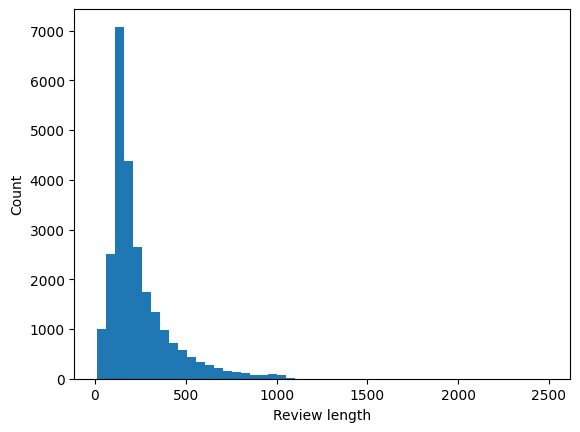

Shapes: (25000, 200) (25000, 200)
Example (pre-padding): [  0   0   0   0  25  91 307  18]


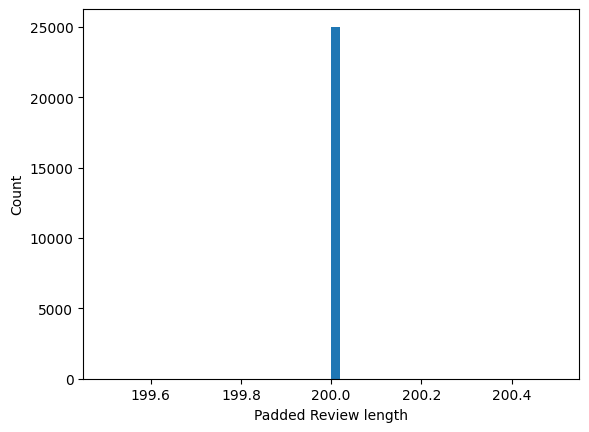

In [ ]:
lengths = [len(r) for r in X_train_raw]
plt.hist(lengths, bins=50); plt.xlabel("Review length"); plt.ylabel("Count"); plt.show()

X_train = pad_sequences(X_train_raw, maxlen=MAXLEN)
X_test  = pad_sequences(X_test_raw,  maxlen=MAXLEN)
print("Shapes:", X_train.shape, X_test.shape)
print("Example (pre-padding):", pad_sequences([[25, 91, 307, 18]], maxlen=8)[0])
padded_lengths = [len(r) for r in X_train]
plt.hist(padded_lengths, bins=50); plt.xlabel("Padded Review length"); plt.ylabel("Count"); plt.show()

**Check yourself:** What shape is one review now? Why does the RNN prefer zeros at the *start*?

## Step 3 — Embedding
An ID like `307` is only a label. The **Embedding layer** gives each ID a learnable vector, so similar words can end up with similar vectors. Shape goes from `(200,)` to `(200, 128)`.

In [ ]:
emb = tf.keras.layers.Embedding(input_dim=VOCAB, output_dim=4)   # tiny: 4 numbers per word
out = emb(tf.constant([[25, 91, 307, 18]]))
print("IDs shape   :", (1, 4), "(batch, time)")
print("Output shape:", out.shape, "(batch, time, embedding_dim)")
print(out.numpy()[0])

IDs shape   : (1, 4) (batch, time)
Output shape: (1, 4, 4) (batch, time, embedding_dim)
[[-0.00371187 -0.0202225  -0.04234255 -0.04330814]
 [ 0.03526647  0.01991543  0.00030552 -0.0089495 ]
 [-0.03930383 -0.02732298 -0.01495804  0.00762546]
 [ 0.03997589  0.02026303  0.00495914  0.02795244]]


**Check yourself:** In the real model `output_dim=128`. What is the output shape for one review of 200 IDs?

## Step 4 — The RNN Equation (forward propagation)
The RNN reads one vector at a time and keeps a memory $h$:

$$h_t = \tanh(W_x x_t + W_h h_{t-1} + b)$$

- $h_0 = 0$ (nothing read yet) &nbsp;|&nbsp; $\tanh$ keeps values in (-1, 1) &nbsp;|&nbsp; the **same** $W_x, W_h, b$ are used at every step.

In [ ]:
def rnn_forward(xs, Wx, Wh, b):
    h, states = 0.0, []
    for x in xs:
        h = np.tanh(Wx * x + Wh * h + b)
        states.append(h)
    return states

Wx, Wh, b = 0.6, 0.4, 0.1
print("x = [0.5, 0.8]      ->", np.round(rnn_forward([0.5, 0.8], Wx, Wh, b), 3))   # expect 0.380, 0.624
print("x = [0.5, 0.1]      ->", np.round(rnn_forward([0.5, 0.1], Wx, Wh, b), 3))
print("x = [0.5, 0.8, 0.2] ->", np.round(rnn_forward([0.5, 0.8, 0.2], Wx, Wh, b), 3))

x = [0.5, 0.8]      -> [0.38  0.624]
x = [0.5, 0.1]      -> [0.38  0.302]
x = [0.5, 0.8, 0.2] -> [0.38  0.624 0.438]


**Check yourself:** Calculate $h_1$ and $h_2$ by hand and match 0.380 and 0.624. When $x_2$ changes from 0.8 to 0.1, which hidden states change, and why?

## Step 5 — From Memory to Decision
The **final** hidden state $h_T$ summarises the whole review (many-to-one). Dense layer then sigmoid:

$$z = W_y h_T + b_y \qquad \hat{y} = \frac{1}{1 + e^{-z}} \qquad \hat{y} \ge 0.5 \Rightarrow \text{Positive}$$

In [ ]:
sigmoid = lambda z: 1 / (1 + np.exp(-z))

h_T = rnn_forward([0.5, 0.8], Wx, Wh, b)[-1]
z = 2.0 * h_T - 0.5
p = sigmoid(z)
print(f"h_T={h_T:.3f}  z={z:.3f}  probability={p:.3f}  ->", "Positive" if p >= 0.5 else "Negative")
print("sigmoid(2.2) =", round(sigmoid(2.2), 3))

h_T=0.624  z=0.749  probability=0.679  -> Positive
sigmoid(2.2) = 0.9


**Check yourself:** Why do we use only $h_T$ and not every $h_t$? Why sigmoid and not tanh at the end?

## Step 6 — Build the Model
```
Embedding(10000→128) → SimpleRNN(128) → Dropout(0.5) → Dense(1, sigmoid)
```
Dropout randomly switches off half the units while training so the model can't just memorise.

In [ ]:
def build_model(max_len=MAXLEN, emb_dim=128, units=128):
    return Sequential([
        Input(shape=(max_len,)),
        Embedding(VOCAB, emb_dim),
        SimpleRNN(units),
        Dropout(0.5),
        Dense(1, activation="sigmoid"),
    ])

model = build_model()
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

# Parameter check (do it by hand first!)
print("Embedding:", VOCAB * 128)
print("SimpleRNN:", 128*128 + 128*128 + 128, " = Wx + Wh + b")
print("Dense    :", 128 + 1)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,313,025 (5.01 MB)

 Trainable params: 1,313,025 (5.01 MB)

 Non-trainable params: 0 (0.00 B)

Embedding: 1280000
SimpleRNN: 32896  = Wx + Wh + b
Dense    : 129


**Check yourself:** Which layer has the most parameters? Where do the 16,384 in $W_x$ come from?

## Step 7 — Training
Per batch: **forward pass** (predict) → **loss** (binary cross-entropy) → **BPTT** (gradients flow back through all 200 steps) → **Adam** updates weights.  
Forward propagation predicts; backpropagation is what learns.

In [ ]:
t0 = time.time()
history = model.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.2)
print(f"Training time: {time.time() - t0:.0f} s")

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 28s 84ms/step - accuracy: 0.5182 - loss: 0.7317 - val_accuracy: 0.5902 - val_loss: 0.6610
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 26s 82ms/step - accuracy: 0.6579 - loss: 0.6248 - val_accuracy: 0.6722 - val_loss: 0.6114
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 26s 82ms/step - accuracy: 0.7778 - loss: 0.4761 - val_accuracy: 0.7746 - val_loss: 0.4815
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 26s 85ms/step - accuracy: 0.8313 - loss: 0.4045 - val_accuracy: 0.7442 - val_loss: 0.5153
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 40s 82ms/step - accuracy: 0.7998 - loss: 0.4501 - val_accuracy: 0.7854 - val_loss: 0.4797
Training time: 161 s


**Check yourself:** What is the difference between *validation* data and *test* data?

## Step 8 — Reading the Results

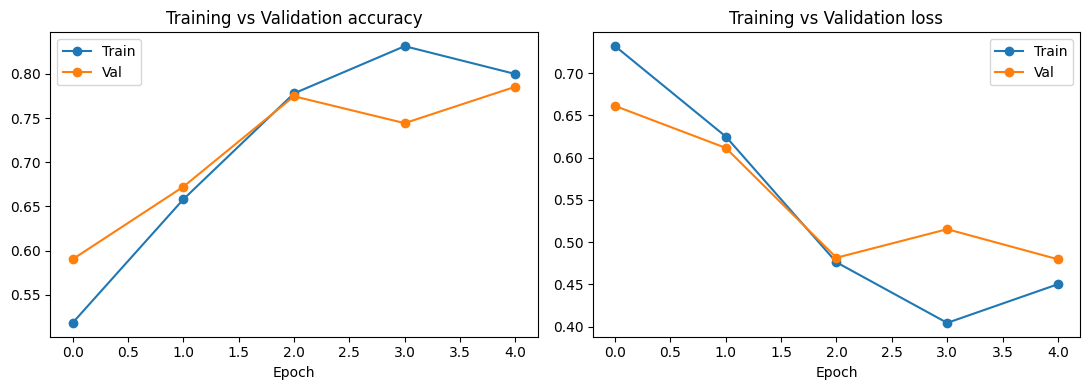

Test accuracy: 0.7912
              precision    recall  f1-score   support

    Negative       0.83      0.73      0.78     12500
    Positive       0.76      0.86      0.80     12500

    accuracy                           0.79     25000
   macro avg       0.80      0.79      0.79     25000
weighted avg       0.80      0.79      0.79     25000



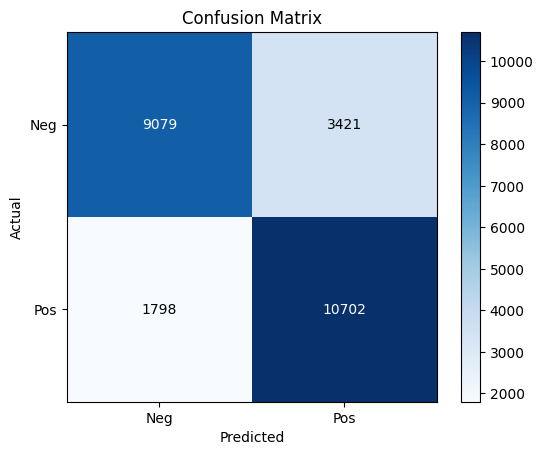

TP=10702 TN=9079 FP=3421 FN=1798


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, m in zip(ax, ["accuracy", "loss"]):
    a.plot(history.history[m], marker="o"); a.plot(history.history["val_" + m], marker="o")
    a.set_title(f"Training vs Validation {m}"); a.set_xlabel("Epoch"); a.legend(["Train", "Val"])
plt.tight_layout(); plt.show()

test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.4f}")

y_prob = model.predict(X_test, verbose=0)
y_pred = (y_prob >= 0.5).astype(int).ravel()
print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"]))

cm = confusion_matrix(y_test, y_pred)
plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xticks([0, 1], ["Neg", "Pos"]); plt.yticks([0, 1], ["Neg", "Pos"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix")
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max()/2 else "black")
plt.show()
tn, fp, fn, tp = cm.ravel(); print(f"TP={tp} TN={tn} FP={fp} FN={fn}")

**Check yourself:** Is the model overfitting? Which is bigger, FP or FN? What do precision and recall mean in plain words?

## Step 9 — Predict Your Own Sentence
Use the **same pipeline as training**: lowercase → IDs (+3) → unknown = 2 → pad to 200. Words outside the 10,000 vocabulary must also map to 2.

In [ ]:
def encode(text):
    words = text.lower().replace(".", "").replace(",", "").replace("!", "").replace("?", "").split()
    ids = [1]                                            # start token
    for w in words:
        i = word_index.get(w)
        ids.append(i + 3 if i is not None and i + 3 < VOCAB else 2)
    return ids

def predict(text):
    p = float(model.predict(pad_sequences([encode(text)], maxlen=MAXLEN), verbose=0)[0][0])
    print(f"{p:.3f} -> {'Positive' if p >= 0.5 else 'Negative':8s} | {text}")
    return p

for s in ["This movie was fantastic and I really enjoyed it",
          "What a terrible film, a complete waste of time",
          "The acting was brilliant and the story was moving",
          "I was bored and the plot made no sense",
          "Not bad, but I expected much more from the director"]:   # tricky: negation
    predict(s)

0.750 -> Positive | This movie was fantastic and I really enjoyed it
0.048 -> Negative | What a terrible film, a complete waste of time
0.319 -> Negative | The acting was brilliant and the story was moving
0.047 -> Negative | I was bored and the plot made no sense
0.076 -> Negative | Not bad, but I expected much more from the director


**Check yourself:** Which sentence was hardest? Why might negation ("not bad") confuse a SimpleRNN?

## Step 10 — Verify: Keras `SimpleRNN` = Our Equation
Take the trained weights out of Keras and recompute $h_T$ with plain NumPy. If the difference is ≈ 0, `SimpleRNN` is *exactly* the formula from Step 4.

In [ ]:
sample = pad_sequences([encode("This movie was fantastic and I really enjoyed it")], maxlen=MAXLEN)

h_keras = tf.keras.Model(model.inputs, model.layers[1].output).predict(sample, verbose=0)[0]

E = model.layers[0].get_weights()[0]
Wx_m, Wh_m, b_m = model.layers[1].get_weights()
h = np.zeros(128)
for tok in sample[0]:
    h = np.tanh(E[tok] @ Wx_m + h @ Wh_m + b_m)

print("Max |manual - Keras| for h_T:", np.abs(h - h_keras).max())
Wy, by = model.layers[3].get_weights()
print("Manual prob:", float(sigmoid(h @ Wy + by)[0]), "| Keras prob:", float(model.predict(sample, verbose=0)[0][0]))

Max |manual - Keras| for h_T: 2.3473255994499453e-07
Manual prob: 0.7497847083906982 | Keras prob: 0.7497847080230713


**Check yourself:** What are the shapes of `Wx_m`, `Wh_m`, `b_m`, and `h`? Why is `h` a vector now and a single number in Step 4?

## Step 11 — Experiments
Change **one thing at a time** and record test accuracy and training time. (Uses 3 epochs to save time.)

In [ ]:
def run(name, max_len=MAXLEN, emb_dim=128, units=128, epochs=3):
    Xtr = pad_sequences(X_train_raw, maxlen=max_len); Xte = pad_sequences(X_test_raw, maxlen=max_len)
    m = build_model(max_len, emb_dim, units)
    m.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    t0 = time.time()
    m.fit(Xtr, y_train, epochs=epochs, batch_size=64, validation_split=0.2, verbose=0)
    t = time.time() - t0
    acc = m.evaluate(Xte, y_test, verbose=0)[1]
    print(f"{name:22s} acc={acc:.4f} time={t:.0f}s")
    return {"Experiment": name, "Setting": f"len={max_len}, emb={emb_dim}, units={units}",
            "Test Acc": round(acc, 4), "Time (s)": round(t)}

results = [run("Baseline")]
results += [run(f"Length {L}", max_len=L) for L in (50, 400)]
results += [run(f"Embedding {E}", emb_dim=E) for E in (32, 64)]
results += [run(f"Units {U}", units=U) for U in (32, 64)]

df = pd.DataFrame(results); df["Observation"] = ""     # fill in your own words
df

Baseline               acc=0.6004 time=95s
Length 50              acc=0.7685 time=31s
Length 400             acc=0.6708 time=187s
Embedding 32           acc=0.5154 time=60s
Embedding 64           acc=0.5139 time=61s
Units 32               acc=0.8320 time=63s
Units 64               acc=0.6859 time=59s


,Experiment,Setting,Test Acc,Time (s),Observation
0,Baseline,"len=200, emb=128, units=128",0.6004,95,
1,Length 50,"len=50, emb=128, units=128",0.7685,31,
2,Length 400,"len=400, emb=128, units=128",0.6708,187,
3,Embedding 32,"len=200, emb=32, units=128",0.5154,60,
4,Embedding 64,"len=200, emb=64, units=128",0.5139,61,
5,Units 32,"len=200, emb=128, units=32",0.8320,63,
6,Units 64,"len=200, emb=128, units=64",0.6859,59,


**Observations (write your own):**
- Length 50 vs 400: …
- Embedding size: …
- RNN units: …

### Keep these numbers: next lab we replace `SimpleRNN` with `LSTM` and compare against this baseline.

---
### Lab Questions
1. Why can an RNN not process a raw text string?
An RNN understands numbers, not words directly.
So, we convert words into numbers before giving them to the RNN.
2. Why do we use an embedding layer?
An embedding layer converts words into number vectors.
It helps the model understand the meaning of words.
3. What is the role of $h_{t-1}$?
h_{t−1} is the hidden state from the previous time step.
It carries information from earlier words to the current word.
4. Why are the same recurrent weights reused at every time step?
The same weights are used to process every word in a sentence.
This reduces the number of parameters and keeps learning consistent.
5. What is $h_0$ and why?
h_0 is the initial hidden state, usually set to zeros.
It gives the RNN a starting point before reading any words.
6. Why is the final hidden state used for classification?
The final hidden state contains information learned from the sequence.
We use it to predict the sentence's class, such as positive or negative.
7. Why sigmoid in the last layer?
Sigmoid converts the output into a value between 0 and 1.
This value can represent the probability of a positive or negative class.